In [9]:
#Requirements

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

import joblib

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GroupShuffleSplit
from scipy.ndimage import median_filter, uniform_filter1d
from scipy.signal import savgol_filter, butter, sosfiltfilt, detrend

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import  StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_absolute_error, r2_score, mean_squared_error



#"Random common shapes with noise - data generation"

rng = np.random.default_rng(42)


def generate_clean_signal(variant, length_per_section=100):

    n = length_per_section
    offset = rng.uniform(-0.5, 0.5)

    # Flat signal
    flat = np.full(n, 10 + offset)

    # Trend signal
    x = np.arange(n)
    trend = 10 + offset + 0.04 * x

    # Peak
    center = n / 2 + rng.uniform(-8, 8)
    width = rng.uniform(12, 18)
    peak = (
        14 + offset
        + 4 * np.exp(-0.5 * ((x - center) / width) ** 2)
    )

    # Change in the signal level - Step
    step = np.full(n, 14 + offset)
    step[n // 2:] = 18 + offset

    # Flat signal but at a different level
    flat_new = np.full(n, 18 + offset)

    return np.concatenate([flat, trend, peak, step, flat_new])

#Lets add noise to the clean signal of 3 different types:
def add_noise(clean_signal, noise_type, strength):

    if noise_type == "random":
        noise = rng.normal(0, strength, len(clean_signal))

    elif noise_type == "spikes":
        noise = rng.normal(0, 0.15 * strength, len(clean_signal))

        spike_count = max(1, int(len(clean_signal) * 0.04))
        positions = rng.choice(
            len(clean_signal), size=spike_count, replace=False
        )
        noise[positions] += rng.choice(
            [-1, 1], size=spike_count
        ) * 4 * strength

    elif noise_type == "drift":
        # Gradual change in the noise level across the signal.
        drift = np.linspace(
            -2 * strength, 2 * strength, len(clean_signal)
        )
        noise = drift + rng.normal(
            0, 0.15 * strength, len(clean_signal)
        )

    else:
        raise ValueError("Unknown noise type")

    return clean_signal + noise


# 2. Generate full mixed-signal variants with noise

generated_signals = []

noise_types = ["random", "spikes", "drift"]
noise_strengths = [0.3, 0.7, 1.2]

for variant in range(12):

    # Generate one full signal containing all five sections
    clean_signal = generate_clean_signal(variant)

    # Create noisy versions of this signal
    for noise_type in noise_types:
        for strength in noise_strengths:

            noisy_signal = add_noise(
                clean_signal,
                noise_type,
                strength
            )

            # Store everything needed for windowing and filter testing
            generated_signals.append({
                "variant": variant,
                "noise_type": noise_type,
                "noise_strength": strength,
                "clean_signal": clean_signal.copy(),
                "noisy_signal": noisy_signal
            })

print("Total noisy signals:", len(generated_signals))




#Sliding window features
#the window configuration is adjsutable by changing the window size and overlapping step size!
WINDOW_SIZE = 100
STEP_SIZE = 35


def get_window_starts(signal_length):


    starts = list(
        range(0, signal_length - WINDOW_SIZE + 1, STEP_SIZE)
    )

    #last window must be included if otherwise does not fulfill the selection range criteria!!
    final_start = signal_length - WINDOW_SIZE
    if starts[-1] != final_start:
        starts.append(final_start)

    return starts
# Creating Filters with their different settings to be applied

Filter_Config = []

#Median Filter
for size in [5,10,15]:
  Filter_Config.append({
      "name": "Median Filter",
      "filter_window": size,
      "polyorder": np.nan,
      "cutoff": np.nan,
      "filter_order": np.nan })

#Moving Average Filter
for size in [5,10,15]:
  Filter_Config.append({
      "name": "Moving Average",
      "filter_window": size,
      "polyorder": np.nan,
      "cutoff": np.nan,
      "filter_order": np.nan })

#Sav_gol Filter
for size in [5,10,15]:
  for order in [2,3]:
    Filter_Config.append({
        "name": "Savitzky-Golay",
        "filter_window": size,
        "polyorder": order,
        "cutoff": np.nan,
        "filter_order": np.nan })

#Butterworth Filter

for cutoff in [0.05, 0.1, 0.2]:
  for order in [2,3]:
    Filter_Config.append({
        "name": "Butterworth",
        "filter_window": np.nan,
        "polyorder": np.nan,
        "cutoff": cutoff,
        "filter_order": order })

"""#linear detrending Filter

Filter_Config.append({
    "name": "Linear Detrending",
    "filter_window": np.nan,
    "polyorder": np.nan,
    "cutoff": np.nan,
    "filter_order": np.nan })"""
#Lets apply the filters in a loop with different settings and defined configurations!


def apply_filters(signal, filter_config):

  name = filter_config ["name"]

  if name == "Median Filter":
    return median_filter (signal, size= int(filter_config["filter_window"]))

  elif name == "Moving Average":
    return uniform_filter1d(signal,size = int(filter_config["filter_window"]))

  elif name == "Savitzky-Golay":
    return savgol_filter(signal, window_length=int(filter_config["filter_window"]), polyorder=int(filter_config["polyorder"]))

  elif name == "Butterworth":
    sos = butter(int(filter_config["filter_order"]), filter_config["cutoff"], btype='low', output='sos')
    return sosfiltfilt (sos, signal)

  else:
    raise ValueError(f"Unknown filter name: {name}")

# Apply every filter to every window and record performance

results = []

for signal_data in generated_signals:

    clean_signal = signal_data["clean_signal"]
    noisy_signal = signal_data["noisy_signal"]


    window_starts = get_window_starts(len(noisy_signal))

    for start in window_starts:

        end = start + WINDOW_SIZE

        noisy_window = noisy_signal[start:end]
        clean_window = clean_signal[start:end]


        for filter_config in Filter_Config: #which is defined earlier

            filtered_window = apply_filters(
                noisy_window, filter_config
            )


            errors = filtered_window - clean_window

            rmse = np.sqrt(np.mean(errors ** 2))
            mae = np.mean(np.abs(errors))

            #### NEW: Calculate SNR in decibels, following the paper's approach.
            #### Compare the clean window with the filtered window.
            signal_power = np.sum(clean_window ** 2)
            error_power = np.sum(errors ** 2)

            if error_power > 0:
                snr = 10 * np.log10(signal_power / error_power)
            else:
                snr = np.inf  # Perfect reconstruction: no remaining error.


            results.append({
                "variant": signal_data["variant"],
                "noise_type": signal_data["noise_type"],
                "noise_strength": signal_data["noise_strength"],
                "window_start": start,

                "window_mean": np.mean(noisy_window),
                "window_std": np.std(noisy_window),
                "window_range": np.ptp(noisy_window), #Peak to Peak range
                "window_slope": np.polyfit(
                    np.arange(len(noisy_window)),
                    noisy_window,
                    1
                )[0], #Slope information for the model to see how the selected window is behaving (increasing or decreasing etc)
                "window_roughness": np.mean(
                    np.abs(np.diff(noisy_window, n=2))
                ), #Roughness values need to tell the changes (abrupt or smooth) so model will learn the pattern of the change and corresponding filters etc information
                "filter_name": filter_config["name"],
                "filter_window": filter_config["filter_window"],
                "polyorder": filter_config["polyorder"],
                "cutoff": filter_config["cutoff"],
                "filter_order": filter_config["filter_order"],

                "RMSE": rmse,
                "MAE": mae,

                #### NEW: Store the SNR result for each filter configuration.
                "SNR": snr
            })


results_df = pd.DataFrame(results)

results_df.insert(0, "windows_id", "signal_" + results_df["variant"].astype(str)+ "_" +results_df["noise_strength"].astype(str)+ "_" + results_df["window_start"].astype(str))

results_df.to_csv("filter_results.csv", index=False)


#grouping and defining the min max SNR to define scoring later

window_groups = results_df.groupby(
    ["variant", "noise_type", "noise_strength", "window_start"]
)["SNR"]

min_error = window_groups.transform("min")
max_error = window_groups.transform("max")

error_range = max_error - min_error

performance_score =  np.where(
    error_range > 0,
    100 * (max_error - results_df["SNR"]) / error_range,
    100
)
results_df ["performance_score"]= performance_score



#### NEW: SNR is now available to identify the best filter for each window.
#### The highest SNR represents the lowest remaining error relative to the clean signal.

results_df.to_csv("filter_results.csv", index=False)
print("result rows:", len(results_df))
print(results_df.head())

#For classification we need discrete labels, so we will use the best filter for each window as the label for training the classifier.
best_filter_indices = results_df.groupby(
    ["variant", "noise_type", "noise_strength", "window_start"]
)["SNR"].idxmax()

best_filters_df = results_df.loc[best_filter_indices].copy()

best_filters_df["best_filter"] = (
    best_filters_df["filter_name"].astype(str) + "_" +
    best_filters_df["filter_window"].astype(str) + "_" +
    best_filters_df["polyorder"].astype(str) + "_" +
    best_filters_df["cutoff"].astype(str) + "_" +
    best_filters_df["filter_order"].astype(str)
)

#lets split the data for training and testing

splitter = GroupShuffleSplit(
    n_splits=1, test_size=0.40, random_state=42
)
#now the split will be done based on the variant column, so that all windows from the same signal variant are either in the training or testing set, but not both.
split_results = splitter.split(best_filters_df, groups= best_filters_df ["variant"])

train_part, test_part = next (split_results)


train_df_classifier = best_filters_df.iloc[train_part].copy()
test_df_classifier= best_filters_df.iloc[test_part].copy()


train_df_classifier.to_csv("train_classifier.csv", index=False)
test_df_classifier.to_csv("test_classifier.csv", index=False)


# preparing model and data

# preparing data for the model

numerical_features = [
    "window_mean",
    "window_std",
    "window_range",
    "window_slope",
    "window_roughness"
]


feature_columns =  numerical_features

X_train = train_df_classifier[feature_columns]
y_train = train_df_classifier["best_filter"]

X_test = test_df_classifier[feature_columns]
y_test = test_df_classifier["best_filter"]

preprocessor = ColumnTransformer(
    transformers=[
        ("numbers", SimpleImputer(strategy="median"), numerical_features)
    ]
)






Total noisy signals: 108
result rows: 25272
       windows_id  variant noise_type  noise_strength  window_start  \
0  signal_0_0.3_0        0     random             0.3             0   
1  signal_0_0.3_0        0     random             0.3             0   
2  signal_0_0.3_0        0     random             0.3             0   
3  signal_0_0.3_0        0     random             0.3             0   
4  signal_0_0.3_0        0     random             0.3             0   

   window_mean  window_std  window_range  window_slope  window_roughness  \
0    10.260524    0.232364      1.227805     -0.001117          0.423296   
1    10.260524    0.232364      1.227805     -0.001117          0.423296   
2    10.260524    0.232364      1.227805     -0.001117          0.423296   
3    10.260524    0.232364      1.227805     -0.001117          0.423296   
4    10.260524    0.232364      1.227805     -0.001117          0.423296   

      filter_name  filter_window  polyorder  cutoff  filter_order      R

In [10]:
param_grid = {
    "classifier__n_estimators": [50, 100, 200],
    "classifier__min_samples_leaf": [1, 2, 4],
    "classifier__max_depth": [None, 10, 20],
}


from sklearn.model_selection import RandomizedSearchCV #gridsearchCV took too long, lets test with this

grid_search = RandomizedSearchCV(
    estimator=Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", RandomForestClassifier(
            random_state=42,
            n_jobs=1
        ))
    ]),
    param_distributions=param_grid,
    scoring="f1_weighted",
    cv=5,
    verbose =1
)

grid_search.fit(X_train, y_train)
train_df_classifier["predicted_filter"] = grid_search.predict(X_train)
test_df_classifier["predicted_filter"] = grid_search.predict(X_test)

from sklearn.metrics import accuracy_score, classification_report

y_train_pred = grid_search.predict(X_train)
y_test_pred = grid_search.predict(X_test)

print("\nBEST CROSS-VALIDATION F1")
print(grid_search.best_score_)

print("\nTRAIN vs TEST COMPARISON")
print("Training Accuracy:", accuracy_score(y_train, y_train_pred))
print("Test Accuracy:", accuracy_score(y_test, y_test_pred))

print("\nTEST CLASSIFICATION REPORT")
print(classification_report(y_test, y_test_pred, zero_division=0))

joblib.dump({
    "model": grid_search.best_estimator_,
    "feature_columns": feature_columns
}, "Signal_processing_classifer.joblib")

Fitting 5 folds for each of 10 candidates, totalling 50 fits


c:\ProgramData\anaconda3\Lib\site-packages\sklearn\model_selection\_split.py:811: UserWarning: The least populated class in y has only 1 members, which is less than n_splits=5.
  warnings.warn(



BEST CROSS-VALIDATION F1
0.504479408684886

TRAIN vs TEST COMPARISON
Training Accuracy: 0.9645909645909646
Test Accuracy: 0.5111111111111111

TEST CLASSIFICATION REPORT
                                 precision    recall  f1-score   support

   Butterworth_nan_nan_0.05_2.0       0.13      0.05      0.07        44
   Butterworth_nan_nan_0.05_3.0       0.12      0.09      0.10        33
    Butterworth_nan_nan_0.1_2.0       0.10      0.10      0.10        10
    Butterworth_nan_nan_0.1_3.0       0.00      0.00      0.00         9
    Butterworth_nan_nan_0.2_3.0       0.00      0.00      0.00         1
 Median Filter_10.0_nan_nan_nan       0.62      0.48      0.54        50
 Median Filter_15.0_nan_nan_nan       0.63      0.78      0.69       170
  Median Filter_5.0_nan_nan_nan       0.53      0.43      0.48        72
Moving Average_10.0_nan_nan_nan       0.32      0.42      0.36        19
Moving Average_15.0_nan_nan_nan       0.50      0.63      0.56        90
Savitzky-Golay_10.0_2.0_na

['Signal_processing_classifer.joblib']

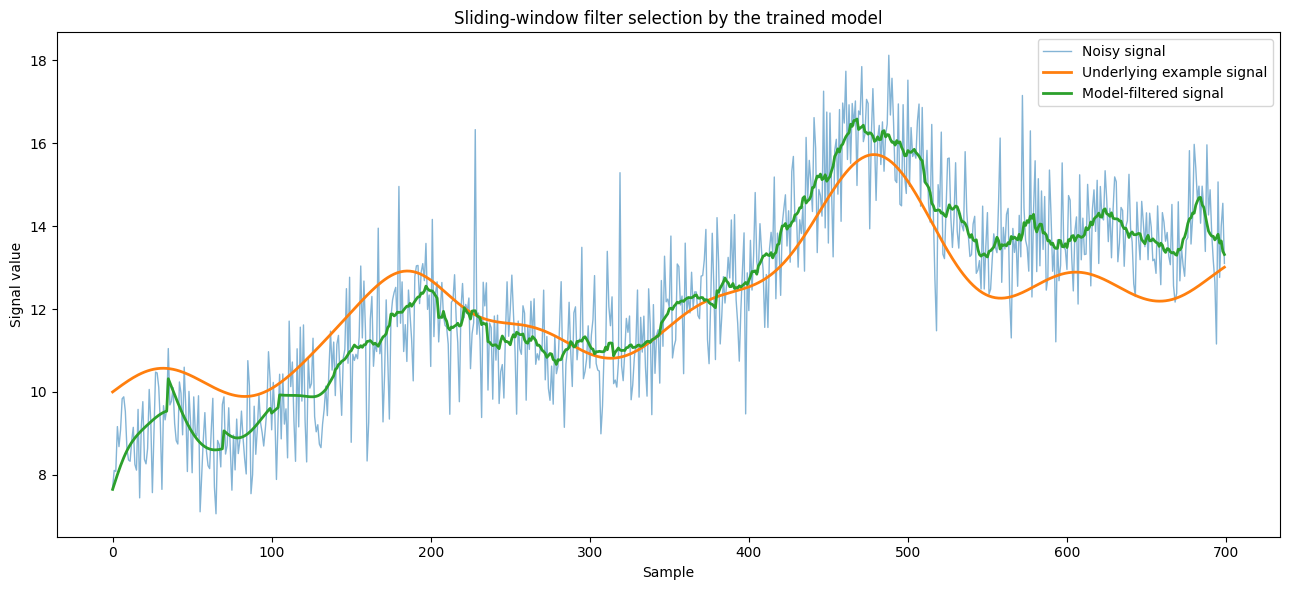

Filter chosen for each window:
Samples 0-99: Butterworth (cutoff=0.05, order=3)
Samples 35-134: Butterworth (cutoff=0.05, order=3)
Samples 70-169: Butterworth (cutoff=0.05, order=2)
Samples 105-204: Butterworth (cutoff=0.05, order=2)
Samples 140-239: Moving Average (window=15)
Samples 175-274: Moving Average (window=15)
Samples 210-309: Moving Average (window=15)
Samples 245-344: Moving Average (window=15)
Samples 280-379: Butterworth (cutoff=0.05, order=2)
Samples 315-414: Butterworth (cutoff=0.05, order=2)
Samples 350-449: Moving Average (window=15)
Samples 385-484: Moving Average (window=15)
Samples 420-519: Moving Average (window=15)
Samples 455-554: Moving Average (window=15)
Samples 490-589: Moving Average (window=15)
Samples 525-624: Moving Average (window=15)
Samples 560-659: Moving Average (window=15)
Samples 595-694: Moving Average (window=15)
Samples 600-699: Moving Average (window=15)
Average SNR of the signal:
24.17

Highest SNR:
SNR                             33.292019
n

In [16]:
# Load the model and use on any signal with same input features or define the features as per the model requirements

saved_model = joblib.load("Signal_processing_classifer.joblib")
model = saved_model ["model"]
feature_columns = saved_model["feature_columns"]

# These must match the window settings used when training.
WINDOW_SIZE = 100
STEP_SIZE = 35

# a demo signal to test the model again - real case simulation

rng = np.random.default_rng(10)  # Makes this example repeatable.
time = np.arange(700)

# A slowly changing baseline with broad peaks and a small oscillation.
clean_signal = (
    10
    + 0.004 * time
    + 2.5 * np.exp(-0.5 * ((time - 190) / 28) ** 2)
    + 3.5 * np.exp(-0.5 * ((time - 470) / 42) ** 2)
    + 0.45 * np.sin(2 * np.pi * time / 115)
)

# Add measurement noise plus a gradual sensor-baseline drift.
noise = rng.normal(0, 1, len(time))
drift = np.linspace(-1.2, 1.6, len(time))
noisy_signal = clean_signal + noise + drift

# Add a few occasional spikes, as can happen in sensor measurements.
spike_positions = rng.choice(len(time), size=8, replace=False)
noisy_signal[spike_positions] += rng.choice([-1, 1], size=8) * rng.uniform(2, 3.5, size=8)

#deine the same filter configuration used in training - as a tool to apply

FILTER_CONFIGS = []

for size in [5, 10, 15]:
    FILTER_CONFIGS.append({"filter_name": "Median", "filter_window": size,
                           "polyorder": np.nan, "cutoff": np.nan, "filter_order": np.nan})

for size in [5, 10, 15]:
    FILTER_CONFIGS.append({"filter_name": "Moving Average", "filter_window": size,
                           "polyorder": np.nan, "cutoff": np.nan, "filter_order": np.nan})

for size in [5, 10, 15]:
    FILTER_CONFIGS.append({"filter_name": "Savitzky-Golay", "filter_window": size,
                           "polyorder": 2, "cutoff": np.nan, "filter_order": np.nan})

for cutoff in [0.05, 0.1, 0.2]:
    for order in [2, 3]:
        FILTER_CONFIGS.append({"filter_name": "Butterworth", "filter_window": np.nan,
                               "polyorder": np.nan, "cutoff": cutoff, "filter_order": order})


#Applying the filter

def apply_filter(signal, config):

    name = config["filter_name"]

    if name == "Median":
        return median_filter(signal, size=int(config["filter_window"]))
    elif name == "Moving Average":
        return uniform_filter1d(signal, size=int(config["filter_window"]))
    elif name == "Savitzky-Golay":
        return savgol_filter(signal, window_length=int(config["filter_window"]),
                             polyorder=int(config["polyorder"]))
    elif name == "Butterworth":
        sos = butter(int(config["filter_order"]), config["cutoff"],
                     btype="low", output="sos")
        return sosfiltfilt(sos, signal)

    raise ValueError("Unknown filter")


# Window sliding settings

starts = list(range(0, len(noisy_signal) - WINDOW_SIZE + 1, STEP_SIZE))
final_start = len(noisy_signal) - WINDOW_SIZE
if starts[-1] != final_start:
    starts.append(final_start)

# Overlapping windows are combined by averaging their filtered values.
filtered_total = np.zeros(len(noisy_signal))
coverage = np.zeros(len(noisy_signal))
selected_filters = []

for start in starts:
    end = start + WINDOW_SIZE
    noisy_window = noisy_signal[start:end]

    # These are the same signal features the model saw during training.
    window_features = {
        "window_mean": np.mean(noisy_window),
        "window_std": np.std(noisy_window),
        "window_range": np.ptp(noisy_window),
        "window_slope": np.polyfit(np.arange(WINDOW_SIZE), noisy_window, 1)[0],
        "window_roughness": np.std(np.diff(noisy_window)),
    }

    window_df = pd.DataFrame([window_features])
    window_df = window_df[feature_columns]

    predicted_filter = model.predict(window_df)[0]

    # Match the predicted label to its filter configuration.
    config_df = pd.DataFrame(FILTER_CONFIGS)

    config_df["best_filter"] = (
        config_df["filter_name"].astype(str) + "_" +
        config_df["filter_window"].astype(str) + "_" +
        config_df["polyorder"].astype(str) + "_" +
        config_df["cutoff"].astype(str) + "_" +
        config_df["filter_order"].astype(str)
    )

    config_lookup = dict(zip(config_df["best_filter"], FILTER_CONFIGS))

    best_config = config_lookup[predicted_filter]

    filtered_window = apply_filter(noisy_window, best_config)

    filtered_total[start:end] += filtered_window
    coverage[start:end] += 1
    selected_filters.append((start, best_config["filter_name"],
                             best_config["filter_window"],
                             best_config["cutoff"],
                             best_config["filter_order"]))

filtered_signal = filtered_total / coverage

#Visualization will show the original , signal with noise, and the filtered signal

plt.figure(figsize=(13, 6))
plt.plot(time, noisy_signal, label="Noisy signal", alpha=0.55, linewidth=1)
plt.plot(time, clean_signal, label="Underlying example signal", linewidth=2)
plt.plot(time, filtered_signal, label="Model-filtered signal", linewidth=2)
plt.xlabel("Sample")
plt.ylabel("Signal value")
plt.title("Sliding-window filter selection by the trained model")
plt.legend()
plt.tight_layout()
plt.show()

# Optional: show which filter family the model chose in each window.
print("Filter chosen for each window:")
for start, name, size, cutoff, order in selected_filters:
    settings = []
    if pd.notna(size):
        settings.append(f"window={int(size)}")
    if pd.notna(cutoff):
        settings.append(f"cutoff={cutoff}")
    if pd.notna(order):
        settings.append(f"order={int(order)}")
    extra = ", ".join(settings)
    print(f"Samples {start}-{start + WINDOW_SIZE - 1}: {name}" + (f" ({extra})" if extra else ""))

# Create one selected-filter entry for every sample.
selected_filter_column = [[] for _ in range(len(time))]

for start, name, size, cutoff, order in selected_filters:
    filter_label = f"{name}_{size}_{cutoff}_{order}"

    selected_filter_column[start:start + WINDOW_SIZE] = [
        values + [filter_label]
        for values in selected_filter_column[start:start + WINDOW_SIZE]
    ]

# Combine filter names where windows overlap.
selected_filter_column = [
    "; ".join(dict.fromkeys(filters))
    for filters in selected_filter_column
]

# Create one SNR entry for every sample.
sample_snr = [[] for _ in range(len(time))]

for start in starts:
    end = start + WINDOW_SIZE

    clean_window = clean_signal[start:end]
    filtered_window = filtered_signal[start:end]

    error_power = np.sum((clean_window - filtered_window) ** 2)
    signal_power = np.sum(clean_window ** 2)

    window_snr = 10 * np.log10(signal_power / error_power) if error_power > 0 else np.inf

    for sample in range(start, end):
        sample_snr[sample].append(window_snr)

# Average SNR values where windows overlap.
avg_snr = [
    np.mean(values) if values else np.nan
    for values in sample_snr
]

results_df = pd.DataFrame({
    "sample": time,
    "noise_type" : noise_type,
    "clean_signal": clean_signal,
    "noisy_signal": noisy_signal,
    "filtered_signal": filtered_signal,
    "selected_filter": selected_filter_column,
    "SNR": avg_snr
})

results_df.to_csv("classifier_results_new.csv", index=False)
print(f"Average SNR of the signal:\n{results_df['SNR'].mean():.2f}")

print("\nHighest SNR:")
print(results_df.loc[results_df["SNR"].idxmax(), ["SNR", "noise_type", "selected_filter"]])

print("\nLowest SNR:")
print(results_df.loc[results_df["SNR"].idxmin(), ["SNR", "noise_type", "selected_filter"]])

#also checking the noise_type and the filter performed worst
print("\nLowest 10 SNR values:")

print(results_df.nsmallest(10, "SNR")[["SNR","noise_type", "selected_filter"]])

print("\nHighest 10 SNR values:")
print(results_df.nlargest(10, "SNR") [["SNR", "noise_type", "selected_filter"]])


                     Feature  Importance
4  numbers__window_roughness    0.263285
0       numbers__window_mean    0.200974
2      numbers__window_range    0.193314
1        numbers__window_std    0.188528
3      numbers__window_slope    0.153900


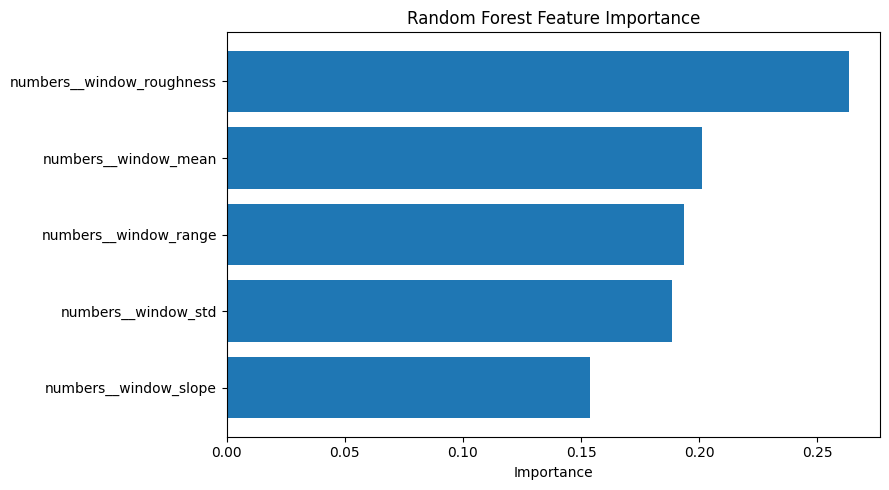

In [20]:
#feature_Importance!
# Confusion matrix
# Heat map to check which inputs are working best slecting the best features
#
rf_model = model.named_steps["classifier"]

importance = pd.DataFrame({
    "Feature": model.named_steps["preprocessor"].get_feature_names_out(),
    "Importance": rf_model.feature_importances_
})

importance = importance.sort_values(
    by="Importance", ascending=False
)

print(importance)
plt.figure(figsize=(9, 5))
plt.barh(importance["Feature"], importance["Importance"])
plt.xlabel("Importance")
plt.title("Random Forest Feature Importance")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()
#Checking how much the filter category wins when the model was trained




Best filters in training data:
filter_name
Median Filter     400
Butterworth       147
Moving Average    146
Savitzky-Golay    126
Name: count, dtype: int64
filter_name
Median Filter     48.840049
Butterworth       17.948718
Moving Average    17.826618
Savitzky-Golay    15.384615
Name: proportion, dtype: float64

Best filters in testing data:
filter_name
Median Filter     292
Moving Average    109
Butterworth        97
Savitzky-Golay     87
Name: count, dtype: int64
filter_name
Median Filter     49.914530
Moving Average    18.632479
Butterworth       16.581197
Savitzky-Golay    14.871795
Name: proportion, dtype: float64

Classifier-selected filter distribution:
selected_filter
Moving Average_15_nan_nan    555
Butterworth_nan_0.05_2       270
Butterworth_nan_0.05_3       135
Name: count, dtype: int64

Classifier-selected filter percentages:
selected_filter
Moving Average_15_nan_nan    57.8125
Butterworth_nan_0.05_2       28.1250
Butterworth_nan_0.05_3       14.0625
Name: count, dtype: 

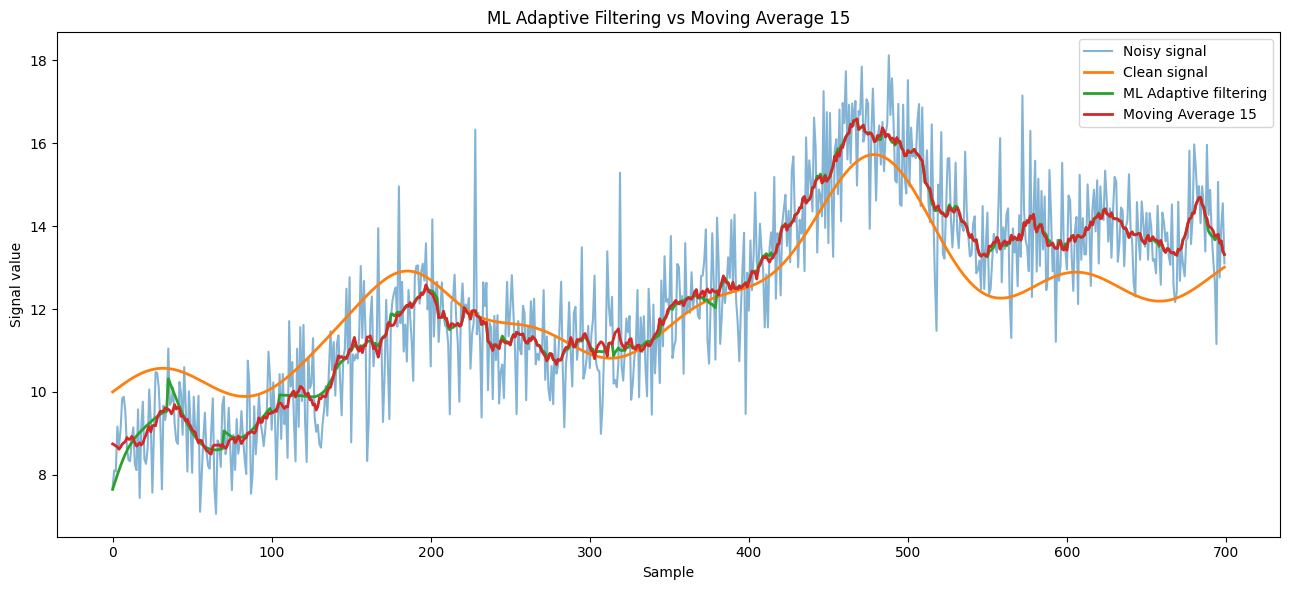

In [21]:

# Best filter distribution in training data
print("\nBest filters in training data:")
print(train_df_classifier["filter_name"].value_counts())
print(train_df_classifier["filter_name"].value_counts(normalize=True) * 100)



# Best filter distribution in testing data
print("\nBest filters in testing data:")
print(test_df_classifier["filter_name"].value_counts())
print(test_df_classifier["filter_name"].value_counts(normalize=True) * 100)


# Now for the trained joblib model



filter_counts = (
    results_df["selected_filter"]
    .str.split("; ")
    .explode()
    .value_counts()
)

print("\nClassifier-selected filter distribution:")
print(filter_counts)

print("\nClassifier-selected filter percentages:")
print(filter_counts / filter_counts.sum() * 100)


# Comparing the SNR of the ML model and Moving Average 15

# Apply Moving Average (window size 15) to the complete noisy signal
moving_average_signal = uniform_filter1d(noisy_signal, size=15)

# Calculate SNR
error_power = np.sum((clean_signal - moving_average_signal) ** 2)
signal_power = np.sum(clean_signal ** 2)

moving_average_snr = 10 * np.log10(signal_power / error_power)

print(f"Moving Average SNR: {moving_average_snr:.2f} dB")


adaptive_error_power = np.sum((clean_signal - filtered_signal) ** 2)
adaptive_signal_power = np.sum(clean_signal ** 2)

adaptive_snr = 10 * np.log10(adaptive_signal_power / adaptive_error_power)

print(f"ML Adaptive SNR: {adaptive_snr:.2f} dB")


plt.figure(figsize=(13, 6))

plt.plot(time, noisy_signal, label="Noisy signal", alpha=0.55)
plt.plot(time, clean_signal, label="Clean signal", linewidth=2)
plt.plot(time, filtered_signal, label="ML Adaptive filtering", linewidth=2)
plt.plot(time, moving_average_signal, label="Moving Average 15", linewidth=2)

plt.xlabel("Sample")
plt.ylabel("Signal value")
plt.title("ML Adaptive Filtering vs Moving Average 15")
plt.legend()
plt.tight_layout()
plt.show()